# Contest-Specific EDA: Gap Fading and Event Volatility
Here we analyze two specific phenomena directly related to the "El Concurso de Bolsa" mechanics:
1. **Overnight Gap Fading:** Do opening gaps tend to revert or continue intraday? (Execution Alpha)
2. **Contest Window Volatility:** Is the Oct 13 - Nov 12 window historically a high-variance minefield due to Q3 Earnings?

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

## Data Ingestion (15-Year Horizon)

In [2]:
print("Loading 15 years of stock data from CSVs...")
prices = pd.read_csv("../data/raw/stocks_close_15y.csv", index_col=0, parse_dates=True)
opens = pd.read_csv("../data/raw/stocks_open_15y.csv", index_col=0, parse_dates=True)
volumes = pd.read_csv('../data/raw/stocks_volume_15y.csv', index_col=0, parse_dates=True)

Loading 15 years of stock data from CSVs...


## 1. The Overnight Gap Fade (Execution Alpha)
We calculate the overnight gap (Close T-1 to Open T) and the subsequent intraday return (Open T to Close T).
If they are negatively correlated, the market is fading the gaps.

Analyzing Overnight Gaps...
Total significant gaps analyzed (>1% magnitude): 32677
Probability that a Gap UP (>1%) fades intraday: 60.8%
Probability that a Gap DOWN (<-1%) fades intraday: 58.3%


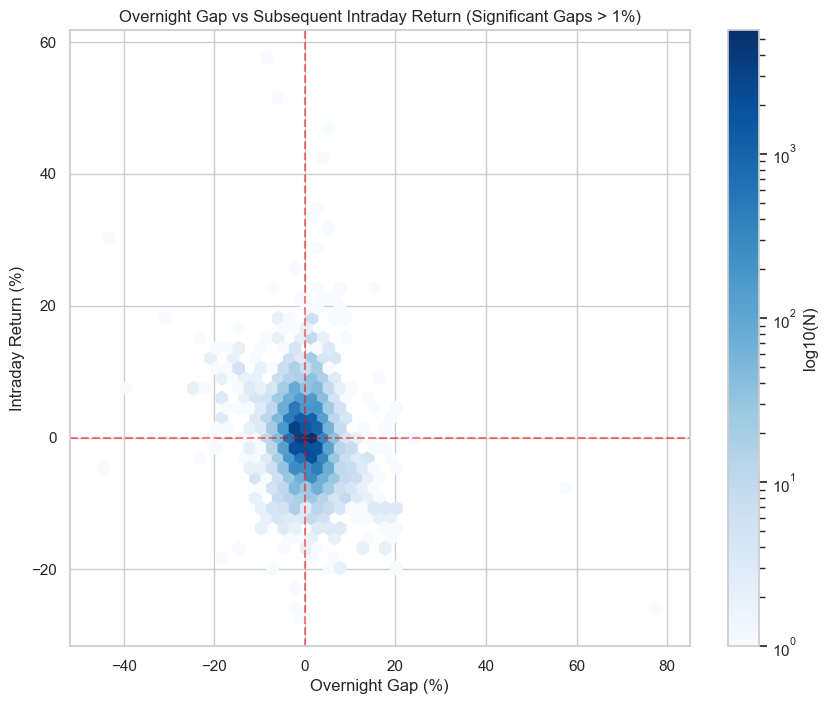

In [3]:
print("Analyzing Overnight Gaps...")
# Shift closes by 1 to get yesterday's close
prev_close = prices.shift(1)

overnight_ret = (opens - prev_close) / prev_close
intraday_ret = (prices - opens) / opens

# Flatten the dataframes to analyze all trades as a single population
gap_df = pd.DataFrame({
    'Overnight_Gap': overnight_ret.unstack(),
    'Intraday_Return': intraday_ret.unstack()
}).dropna()

# Convert to percentages for readability
gap_df *= 100

# Filter for significant gaps (magnitude > 1%)
significant_gaps = gap_df[gap_df['Overnight_Gap'].abs() > 1.0]

# Calculate probability of fade
# Gap Up -> Intraday Down
gap_ups = significant_gaps[significant_gaps['Overnight_Gap'] > 1.0]
prob_fade_up = (gap_ups['Intraday_Return'] < 0).mean()

# Gap Down -> Intraday Up
gap_downs = significant_gaps[significant_gaps['Overnight_Gap'] < -1.0]
prob_fade_down = (gap_downs['Intraday_Return'] > 0).mean()

print(f"Total significant gaps analyzed (>1% magnitude): {len(significant_gaps)}")
print(f"Probability that a Gap UP (>1%) fades intraday: {prob_fade_up:.1%}")
print(f"Probability that a Gap DOWN (<-1%) fades intraday: {prob_fade_down:.1%}")

plt.figure(figsize=(10, 8))
# Hexbin plot handles large datasets well
plt.hexbin(significant_gaps['Overnight_Gap'], significant_gaps['Intraday_Return'], gridsize=50, cmap='Blues', bins='log')
plt.axhline(0, color='red', linestyle='--', alpha=0.5)
plt.axvline(0, color='red', linestyle='--', alpha=0.5)
plt.title("Overnight Gap vs Subsequent Intraday Return (Significant Gaps > 1%)")
plt.xlabel("Overnight Gap (%)")
plt.ylabel("Intraday Return (%)")
cb = plt.colorbar(label='log10(N)')
plt.show()

### Night vs Day Returns (Cumulative)
To visualize where the market historically makes its money, we split the daily return into two isolated components and track their cumulative performance over the 15-year period:
*   **Intraday Return:** `(Close[t] - Open[t]) / Open[t]`
*   **Overnight Return (Gap):** `(Open[t] - Close[t-1]) / Close[t-1]`

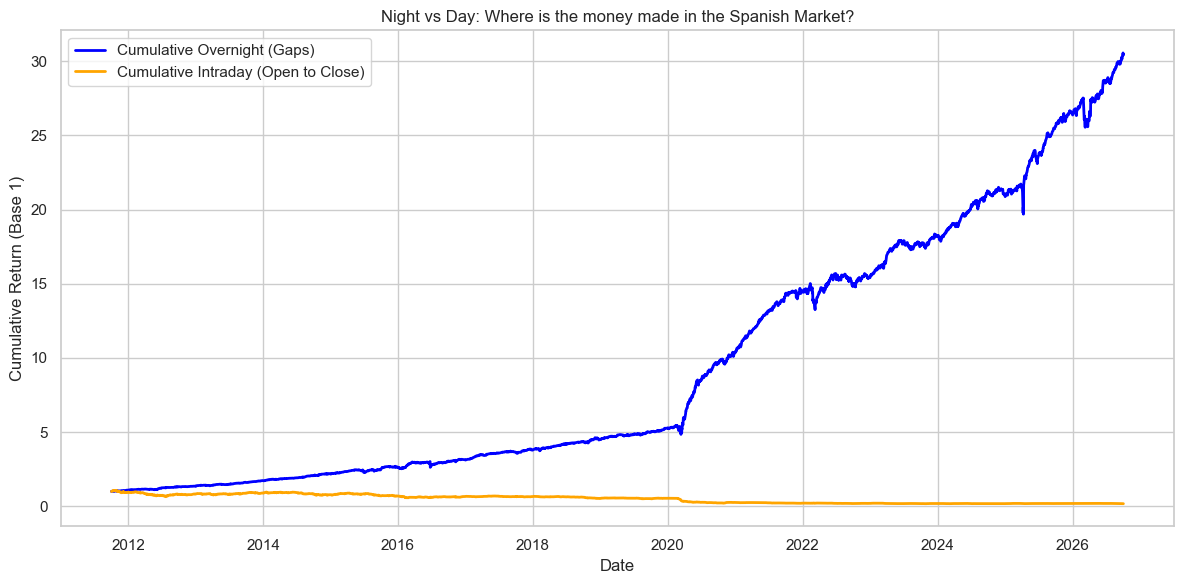

In [4]:
# Calculate the mean cross-sectional return for each day
mean_overnight = overnight_ret.mean(axis=1).fillna(0)
mean_intraday = intraday_ret.mean(axis=1).fillna(0)

# Calculate cumulative performance (Base 1)
cum_overnight = (1 + mean_overnight).cumprod()
cum_intraday = (1 + mean_intraday).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(cum_overnight.index, cum_overnight, label='Cumulative Overnight (Gaps)', color='blue', linewidth=2)
plt.plot(cum_intraday.index, cum_intraday, label='Cumulative Intraday (Open to Close)', color='orange', linewidth=2)
plt.title("Night vs Day: Where is the money made in the Spanish Market?")
plt.ylabel("Cumulative Return (Base 1)")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Event-Driven Volatility (Contest Window)
The contest runs from Oct 13 to Nov 12, covering Q3 earnings. 
We will compare the historical daily volatility inside this specific calendar window vs the rest of the year.

Analyzing Contest Window Volatility (Oct 13 - Nov 12)...
Average Daily Market Volatility INSIDE contest window: 1.8273%
Average Daily Market Volatility OUTSIDE contest window: 1.6663%


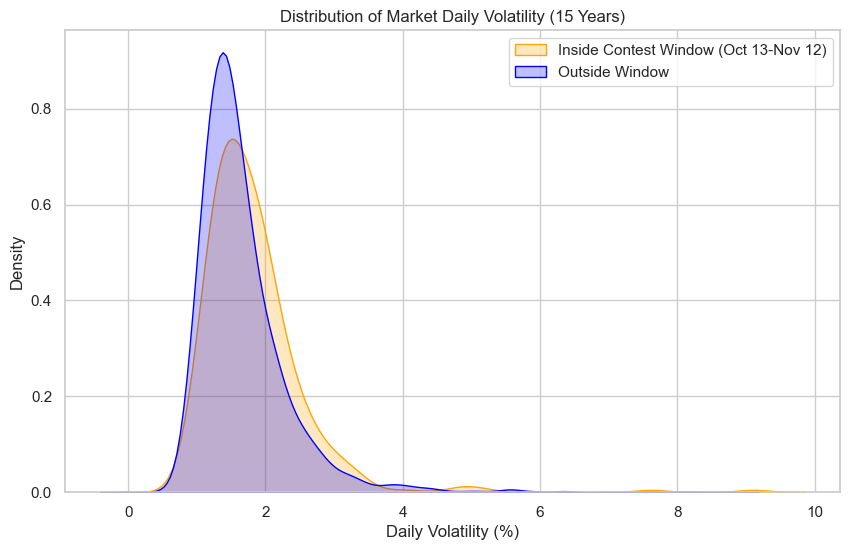

Probability of an extreme volatility spike (>2.5% daily):
- Inside Window: 10.88%
- Outside Window: 8.62%


In [5]:
print("Analyzing Contest Window Volatility (Oct 13 - Nov 12)...")

# Calculate daily volatility (standard deviation of cross-sectional returns) for the entire market
# We use dropna(how='all') to avoid dropping days where only SOME stocks didn't trade (e.g. IPOs)
daily_ret = prices.pct_change().dropna(how='all')

# Create a mask for the contest window (Oct 13 to Nov 12) directly on the return dates
dates = daily_ret.index
in_window = ((dates.month == 10) & (dates.day >= 13)) | ((dates.month == 11) & (dates.day <= 12))

market_daily_volatility = daily_ret.std(axis=1)

vol_inside = market_daily_volatility[in_window]
vol_outside = market_daily_volatility[~in_window]

print(f"Average Daily Market Volatility INSIDE contest window: {vol_inside.mean():.4%}")
print(f"Average Daily Market Volatility OUTSIDE contest window: {vol_outside.mean():.4%}")

# Plotting the distributions
plt.figure(figsize=(10, 6))
sns.kdeplot(vol_inside * 100, label="Inside Contest Window (Oct 13-Nov 12)", fill=True, color='orange')
sns.kdeplot(vol_outside * 100, label="Outside Window", fill=True, color='blue')
plt.title("Distribution of Market Daily Volatility (15 Years)")
plt.xlabel("Daily Volatility (%)")
plt.ylabel("Density")
plt.legend()
plt.show()

# Visualize extreme spikes > 2.5% daily volatility (Crash days)
spike_prob_inside = (vol_inside > 0.025).mean()
spike_prob_outside = (vol_outside > 0.025).mean()

print(f"Probability of an extreme volatility spike (>2.5% daily):")
print(f"- Inside Window: {spike_prob_inside:.2%}")
print(f"- Outside Window: {spike_prob_outside:.2%}")

## 3. Event-Driven Price Impact (Earnings & Macro Events)
We will plot a highly liquid stock (Santander - SAN.MC) over the last 5 years and overlay its historical Earnings Report dates as vertical lines. We will also mark major ECB interest rate shifts.
This visualizes how much earnings reports act as catalysts for price gaps and trend changes in the Spanish market.

Fetching specific data for Event-Driven Analysis...


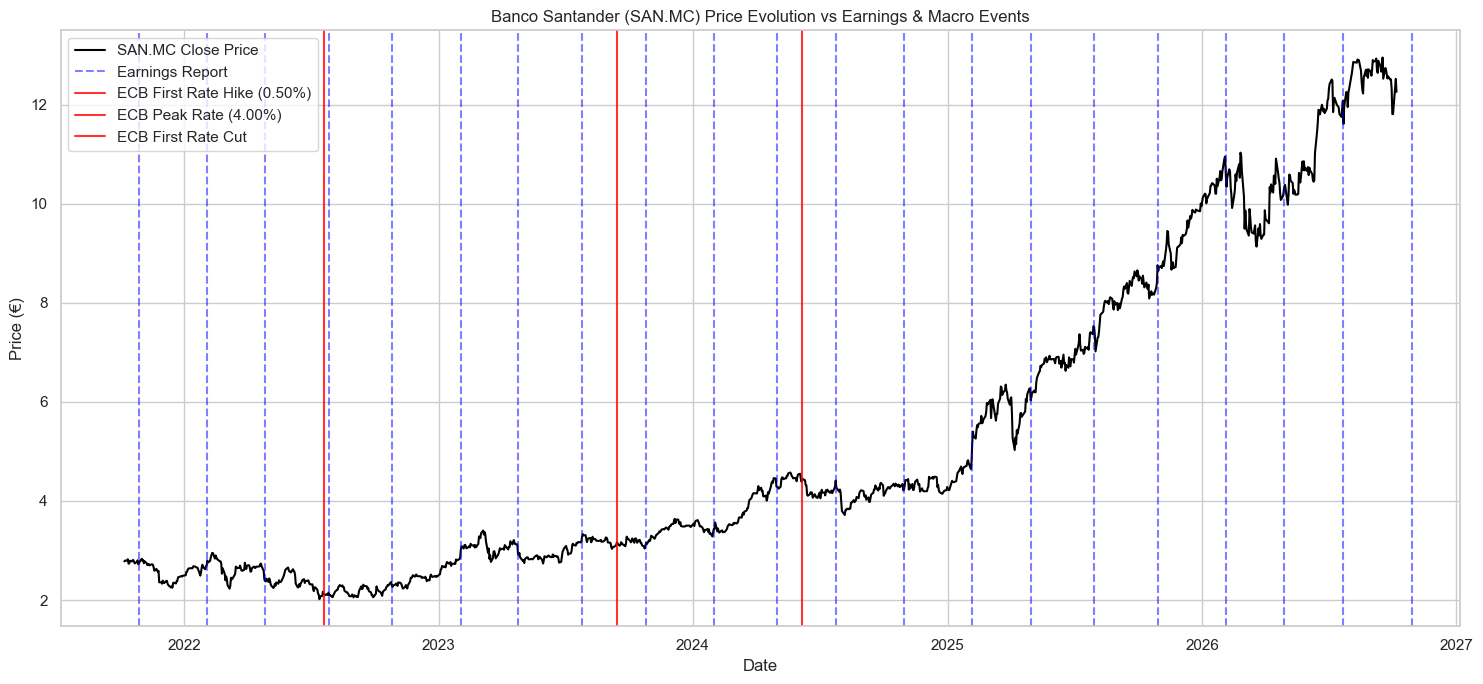

In [6]:
print("Fetching specific data for Event-Driven Analysis...")
import pytz

# Fetch 5 years of data for Santander
tk = yf.Ticker('SAN.MC')
df_san = tk.history(period="5y")

# Fetch earnings dates
earnings = tk.get_earnings_dates()
# Filter earnings to the last 5 years to match the price chart
earnings = earnings[earnings.index >= (pd.Timestamp.now(tz='UTC') - pd.DateOffset(years=5))]

plt.figure(figsize=(15, 7))
plt.plot(df_san.index, df_san['Close'], label='SAN.MC Close Price', color='black', linewidth=1.5)

# Add Earnings Dates
first_earnings = True
for edate in earnings.index:
    # Convert timezone to match the price data
    edate_local = edate.tz_convert(df_san.index.tz)
    plt.axvline(edate_local, color='blue', linestyle='--', alpha=0.5, 
                label='Earnings Report' if first_earnings else "")
    first_earnings = False

# Add some key macro events for context
macro_events = {
    "2022-07-21": "ECB First Rate Hike (0.50%)",
    "2023-09-14": "ECB Peak Rate (4.00%)",
    "2024-06-06": "ECB First Rate Cut"
}

for date_str, label in macro_events.items():
    date_obj = pd.Timestamp(date_str).tz_localize(df_san.index.tz)
    plt.axvline(date_obj, color='red', linestyle='-', alpha=0.8, label=label)

plt.title("Banco Santander (SAN.MC) Price Evolution vs Earnings & Macro Events")
plt.xlabel("Date")
plt.ylabel("Price (€)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 4. Statistical Significance of Earnings Impact
To prove that earnings reports systematically affect the price more than a normal day, we use a statistical test. 
Since earnings can cause a stock to gap UP or DOWN, we look at the **Absolute Return** (magnitude of the move, regardless of direction). 
We will use the **Mann-Whitney U Test** (a non-parametric test ideal for fat-tailed financial data) to compare the volatility of Earnings Days vs Normal Days.

In [7]:
from scipy.stats import mannwhitneyu

# Calculate daily absolute returns (magnitude of volatility)
df_san['Return'] = df_san['Close'].pct_change()
df_san['Abs_Return'] = df_san['Return'].abs() * 100  # Convert to percentage

# Clean timezone data to easily match dates
san_dates = df_san.index.tz_localize(None).normalize()
earn_dates = earnings.index.tz_localize(None).normalize()

# Create a boolean mask: True if it's an earnings day, False otherwise
is_earnings_day = san_dates.isin(earn_dates)

# Split into our two samples
earnings_returns = df_san['Abs_Return'][is_earnings_day].dropna()
normal_returns = df_san['Abs_Return'][~is_earnings_day].dropna()

mean_earn_vol = earnings_returns.mean()
mean_norm_vol = normal_returns.mean()
multiplier = mean_earn_vol / mean_norm_vol

print(f"Mean Absolute Move on Earnings Days: {mean_earn_vol:.2f}%")
print(f"Mean Absolute Move on Normal Days:   {mean_norm_vol:.2f}%")
print(f"Earnings days are {multiplier:.2f}x more volatile on average.\n")

# Run the Mann-Whitney U test (Alternative: 'greater' means we test if earnings vol > normal vol)
stat, p_value = mannwhitneyu(earnings_returns, normal_returns, alternative='greater')

print(f"Mann-Whitney U Statistic: {stat}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("\n✅ STATISTICALLY SIGNIFICANT (p < 0.05):")
    print("We reject the null hypothesis. Earnings reports definitively cause a significant increase in price volatility compared to normal days.")
else:
    print("\n❌ NOT SIGNIFICANT (p >= 0.05):")
    print("We cannot prove that earnings days are structurally more volatile than normal days.")


Mean Absolute Move on Earnings Days: 3.00%
Mean Absolute Move on Normal Days:   1.41%
Earnings days are 2.12x more volatile on average.

Mann-Whitney U Statistic: 18889.0
p-value: 0.000058

✅ STATISTICALLY SIGNIFICANT (p < 0.05):
We reject the null hypothesis. Earnings reports definitively cause a significant increase in price volatility compared to normal days.


## 5. Distribución de Liquidez y Umbrales de Fricción
Antes de programar tu motor de simulación, necesitas saber qué activos de tu universo pueden absorber matemáticamente tu posición óptima sin ser destruidos por la comisión del 0.15% (mínimo 7€).

Calcularemos el volumen negociado en Euros (`Volume * Close`). Evaluaremos el **percentil 10** del volumen histórico para ver el peor escenario de liquidez.
Si disparamos órdenes de **10.000 €** para diluir la comisión fija, descartaremos cualquier activo donde 10.000 € represente más del **1%** de su volumen diario en ese percentil 10 (lo que generaría un slippage masivo).

Total assets evaluated: 48
Assets failing the 10000€ slippage test (Risk of massive friction): 16

        P10_Daily_Euro_Vol Max_Safe_Order (1%)
GSJ.MC             €11,715                €117
ROVI.MC            €26,725                €267
FDR.MC             €35,798                €358
SLR.MC             €74,437                €744
VID.MC            €127,029              €1,270
CASH.MC           €131,510              €1,315
COL.MC            €156,060              €1,561
TUB.MC            €161,810              €1,618
DOM.MC            €172,615              €1,726
TLGO.MC           €184,513              €1,845
FAE.MC            €250,772              €2,508
CIE.MC            €259,381              €2,594
PHM.MC            €479,406              €4,794
ENC.MC            €564,015              €5,640
CAF.MC            €593,033              €5,930
ALM.MC            €838,793              €8,388


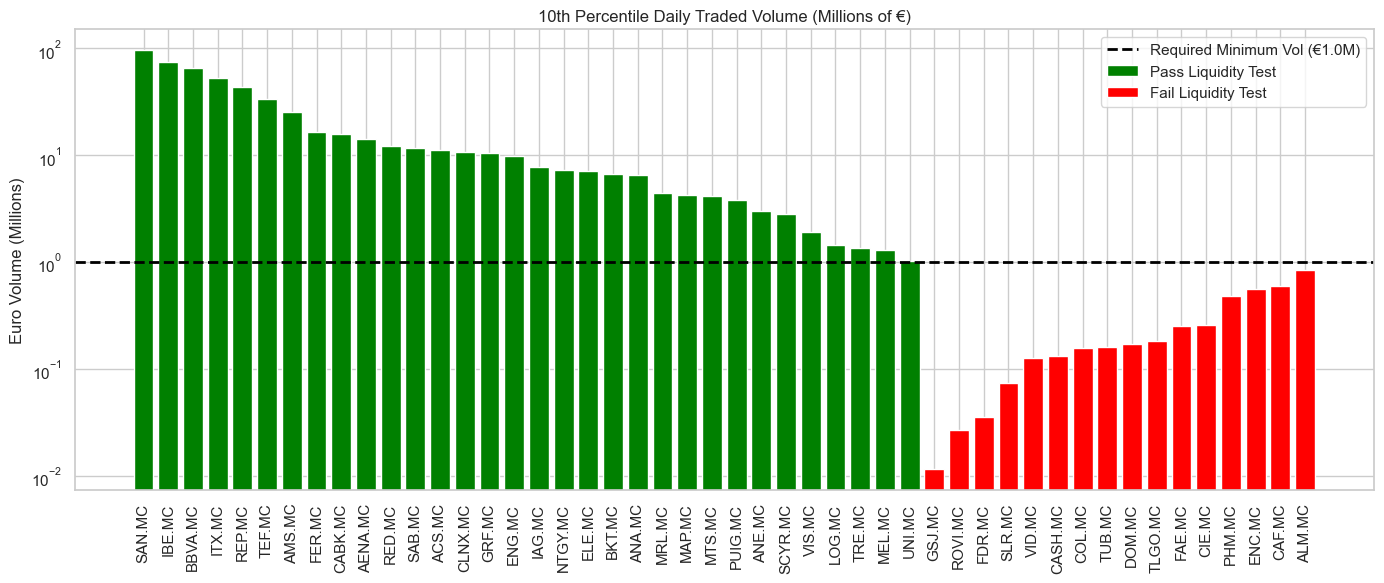

In [8]:
# Calculate Daily Traded Volume in Euros
euro_volume = volumes * prices

# Calculate the 10th percentile of Daily Euro Volume for each asset
# We use the entire 15 year history to find their baseline worst-case liquidity
p10_euro_vol = euro_volume.quantile(0.10)

# Target order size
order_size = 10000

# Slippage limit: Our order cannot exceed 1% of the day's volume
slippage_threshold_ratio = 0.01

# Find the maximum safe order size for each asset at its 10th percentile liquidity
max_safe_order = p10_euro_vol * slippage_threshold_ratio

liquidity_df = pd.DataFrame({
    'P10_Daily_Euro_Vol': p10_euro_vol,
    'Max_Safe_Order (1%)': max_safe_order
})

# Identify assets that FAIL the 10,000€ liquidity test
unsafe_assets = liquidity_df[liquidity_df['Max_Safe_Order (1%)'] < order_size].sort_values('P10_Daily_Euro_Vol')

print(f"Total assets evaluated: {len(liquidity_df)}")
print(f"Assets failing the {order_size}€ slippage test (Risk of massive friction): {len(unsafe_assets)}\n")

if len(unsafe_assets) > 0:
    print("WARNING: The following assets should be excluded or severely size-capped by your Constraints Engine:")
    print(unsafe_assets.to_string(formatters={'P10_Daily_Euro_Vol': '€{:,.0f}'.format, 'Max_Safe_Order (1%)': '€{:,.0f}'.format}))
else:
    print("All assets passed the liquidity threshold!")
    
# Plot the liquidity distribution
plt.figure(figsize=(14, 6))
safe_assets = liquidity_df.drop(unsafe_assets.index).sort_values('P10_Daily_Euro_Vol', ascending=False)

# Bar plot combining safe (green) and unsafe (red)
plt.bar(safe_assets.index, safe_assets['P10_Daily_Euro_Vol'] / 1e6, color='green', label='Pass Liquidity Test')
if len(unsafe_assets) > 0:
    plt.bar(unsafe_assets.index, unsafe_assets['P10_Daily_Euro_Vol'] / 1e6, color='red', label='Fail Liquidity Test')
    
# Draw the threshold line (Volume required to safely absorb a 10k order at 1% slippage = 1,000,000)
required_vol_millions = (order_size / slippage_threshold_ratio) / 1e6
plt.axhline(required_vol_millions, color='black', linestyle='--', linewidth=2, label=f'Required Minimum Vol (€{required_vol_millions}M)')

plt.title("10th Percentile Daily Traded Volume (Millions of €)")
plt.ylabel("Euro Volume (Millions)")
plt.xticks(rotation=90)
plt.legend()
plt.yscale('log') # Log scale helps see the massive difference between SAN and midcaps
plt.tight_layout()
plt.show()

## 4. Análisis de Métricas Baseline (Benchmarks)

Para poder evaluar el rendimiento de nuestras estrategias algorítmicas, necesitamos establecer un **baseline del mercado continuo**. Vamos a analizar qué rendimiento y métricas hubiéramos obtenido si hubiéramos operado estrategias pasivas evaluadas en **ventanas rodantes de 1 mes (22 días de trading)**, exactamente la misma metodología de validación que usaremos para nuestro algoritmo.

Vamos a evaluar tres portfolios:
1. **Buy and Hold (B&H) - Mercado Continuo:** Comprar todo el universo disponible a partes iguales a inicio de mes y mantener.
2. **Constant Rebalanced Portfolio (CRP):** Un portfolio equiponderado de todas las acciones del mercado, que se rebalancea diariamente a pesos iguales.
3. **IBEX 35 Proxy:** Un portfolio equiponderado de las 35 acciones con mayor volumen de cotización (las más líquidas/grandes) rebalanceado diariamente.


In [9]:
import pandas as pd
import numpy as np

# Cargar datos
close_prices = pd.read_csv('../data/raw/stocks_close_15y.csv', index_col=0, parse_dates=True)

# 1. Definir funciones de evaluación para ventanas de 22 días (1 mes)
def evaluate_rolling_windows(daily_returns, window_size=22, step=11):
    results = []
    n_days = len(daily_returns)
    start_points = range(0, n_days - window_size, step)
    
    for start in start_points:
        window_rets = daily_returns.iloc[start:start+window_size].dropna()
        if len(window_rets) < window_size * 0.8:
            continue
            
        ret = (1 + window_rets).prod() - 1
        vol_ann = window_rets.std() * np.sqrt(252) # Volatilidad anualizada
        vol_daily = window_rets.std() # Volatilidad diaria
        
        # Asumimos que el concurso usa Volatilidad anualizada para la métrica
        score = (0.6 * ret) - (0.3 * vol_ann)
        
        results.append({
            'Return_1M': ret, 
            'Vol_Ann': vol_ann, 
            'Vol_Daily': vol_daily, 
            'Score': score
        })
    return pd.DataFrame(results)

def evaluate_buy_and_hold(prices, window_size=22, step=11):
    results = []
    n_days = len(prices)
    start_points = range(0, n_days - window_size, step)
    
    for start in start_points:
        window_prices = prices.iloc[start:start+window_size].dropna(axis=1, how='any')
        if window_prices.empty or len(window_prices) < window_size * 0.8:
            continue
            
        norm_prices = window_prices / window_prices.iloc[0]
        port_val = norm_prices.mean(axis=1)
        port_rets = port_val.pct_change().dropna()
        
        ret = port_val.iloc[-1] - 1
        vol_ann = port_rets.std() * np.sqrt(252)
        vol_daily = port_rets.std()
        
        score = (0.6 * ret) - (0.3 * vol_ann)
        results.append({
            'Return_1M': ret, 
            'Vol_Ann': vol_ann, 
            'Vol_Daily': vol_daily,
            'Score': score
        })
    return pd.DataFrame(results)

# 2. Calcular los portfolios
returns = close_prices.pct_change()

# CRP
crp_returns = returns.mean(axis=1)

# IBEX 35 Proxy
top_35_tickers = close_prices.count().nlargest(35).index
ibex_eq_returns = returns[top_35_tickers].mean(axis=1)

# 3. Evaluar
crp_res = evaluate_rolling_windows(crp_returns)
ibex_res = evaluate_rolling_windows(ibex_eq_returns)
bah_res = evaluate_buy_and_hold(close_prices)

def summarize(df, name):
    print(f"\n{'='*10} {name} {'='*10}")
    print(f"Retorno Promedio Mensual:      {df['Return_1M'].mean()*100:>6.2f}%")
    print(f"Volatilidad Promedio (Anual):  {df['Vol_Ann'].mean()*100:>6.2f}%")
    print(f"Volatilidad Promedio (Diaria): {df['Vol_Daily'].mean()*100:>6.2f}%")
    print(f"Score Concurso (0.6R - 0.3V):  {df['Score'].mean()*100:>6.3f}")
    print(f"Win Rate (Meses positivos):    {(df['Return_1M']>0).mean()*100:>6.2f}%")

summarize(bah_res, "Buy and Hold (Mercado Continuo)")
summarize(crp_res, "Constant Rebalanced Portfolio (Equiponderado)")
summarize(ibex_res, "IBEX 35 Proxy (Top 35 Equiponderado)")



========== Buy and Hold (Mercado Continuo) ==========
Retorno Promedio Mensual:        0.93%
Volatilidad Promedio (Anual):   15.63%
Volatilidad Promedio (Diaria):   0.98%
Score Concurso (0.6R - 0.3V):  -4.130
Win Rate (Meses positivos):     57.93%

========== Constant Rebalanced Portfolio (Equiponderado) ==========
Retorno Promedio Mensual:        1.02%
Volatilidad Promedio (Anual):   15.69%
Volatilidad Promedio (Diaria):   0.99%
Score Concurso (0.6R - 0.3V):  -4.093
Win Rate (Meses positivos):     60.81%

========== IBEX 35 Proxy (Top 35 Equiponderado) ==========
Retorno Promedio Mensual:        1.10%
Volatilidad Promedio (Anual):   16.14%
Volatilidad Promedio (Diaria):   1.02%
Score Concurso (0.6R - 0.3V):  -4.183
Win Rate (Meses positivos):     61.10%
